# 20b. 최종 모델 **테스트** (저장된 모델 사용)

`20a_final_train.ipynb`에서 저장한 `.pkl`을 불러와 labeled에 점수 → 평가
- 모델은 labeled를 학습에 쓴 적 없음 → fold 없이 labeled 전체가 테스트셋
- 파생변수 기준값도 **학습 때 저장한 값**을 그대로 사용 (테스트 데이터로 다시 계산하지 않음)
- 라벨은 채점에만 사용

In [1]:
import pandas as pd
from final_model import test, compare_with_cache
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)

R = test()

[cn7] 테스트 완료: labeled 1,979샷 점수
[rg3] 테스트 완료: labeled 629샷 점수


## 0. 재현 확인 (18번 수치와 같은지)

In [2]:
display(R['check'])

,제품,틀,AP(이번),AP(18번),일치
0,cn7,①,0.373,0.373,O
1,cn7,②,0.212,0.212,O
2,rg3,①,0.024,0.024,O
3,rg3,②,0.048,NaN,-


## 1. 평가 ① 공식 2차 · 행 단위 (팀원 평가 틀)
- **AP**: 주 지표 / **무작위 평균 대비**·**유의**: 무작위 순위 1,000번의 97.5%를 넘으면 O
- **상위 k%**: 점수 상위 k% 행만 검사할 때 잡히는 불량 행
- **F1@5%·10%**: 상위 k%를 불량 판정 / **F1(최적,참고)**: 정답 보고 고른 임계값 → 참고용
- **상한 F1**: LH/RH 같은 입력 행은 같은 판정 → 어떤 모델도 못 넘는 값

In [3]:
display(R['frame1'].round(3))

,제품,행,불량 행,AP,PR-AUC(사다리꼴),무작위 PR-AUC(=불량률),무작위 평균 대비,무작위 상단(97.5%),유의,상위1%,상위2%,상위5%,상위10%,F1@5%,TP@5%,F1@10%,TP@10%,"F1(최적,참고)",상한 F1,F1@5% / 상한,F1(최적) / 상한
0,cn7,1211,17,0.373,0.372,0.014,19.845,0.041,O,6/17,6/17,6/17,8/17,0.154,6,0.116,8,0.522,0.756,0.204,0.691
1,rg3,1182,25,0.024,0.022,0.021,0.892,0.054,-,0/25,0/25,1/25,2/25,0.024,1,0.028,2,0.056,0.667,0.036,0.083


## 2. 평가 ② labeled 전체 · 샷 단위 · 초기허용불량 제외
- **AP / AP_lo~AP_hi**: AP와 부트스트랩 95% 구간, **AP/불량률** = 무작위 대비 배수
- **Run별 / 전체 상위 k%**, **유형별 AP** (가스·미성형)

In [4]:
display(R['frame2'].round(3))

,제품,샷,불량,불량률,AP,AP_lo,AP_hi,AP/불량률,PR-AUC(사다리꼴),Run별 상위5%,Run별 상위10%,전체 상위5%,F1@5%,전체 상위10%,F1@10%,AP_가스,Run별 상위10%_가스,AP_미성형,Run별 상위10%_미성형
0,cn7,1974,15,0.008,0.212,0.011,0.416,27.843,0.211,3/15,4/15,4/15,0.070,5/15,0.047,0.007,1/11,0.751,3/4
1,rg3,591,25,0.042,0.048,0.039,0.075,1.127,0.044,1/25,2/25,1/25,0.036,2/25,0.048,0.032,1/17,0.021,1/8


## 3. 라벨 없이 정한 임계값의 경보 성능 (② 기준)
**경보 비율 ≈ 1 − q** 이면 임계값 보정이 잘 된 것

In [5]:
display(R['threshold'].round(3))

,제품,q,정상 오경보율(가정),경보 수,경보 비율,TP,FP,FN,TN,Precision,Recall,F1,가스 탐지,미성형계열 탐지
0,cn7,0.950,5%,105,0.053,4,101,11,1858,0.038,0.267,0.067,1,3
1,cn7,0.980,2%,45,0.023,3,42,12,1917,0.067,0.200,0.100,0,3
2,cn7,0.990,1%,29,0.015,3,26,12,1933,0.103,0.200,0.136,0,3
3,cn7,0.995,0.5%,19,0.010,3,16,12,1943,0.158,0.200,0.176,0,3
4,cn7,0.999,0.1%,8,0.004,3,5,12,1954,0.375,0.200,0.261,0,3
5,rg3,0.950,5%,38,0.064,1,37,24,529,0.026,0.040,0.032,1,0
6,rg3,0.980,2%,17,0.029,0,17,25,549,0.000,0.000,0.000,0,0
7,rg3,0.990,1%,8,0.014,0,8,25,558,0.000,0.000,0.000,0,0
8,rg3,0.995,0.5%,5,0.008,0,5,25,561,0.000,0.000,0.000,0,0
9,rg3,0.999,0.1%,3,0.005,0,3,25,563,0.000,0.000,0.000,0,0


## PR-AUC · PR 곡선
| 지표 | 계산 | 특징 |
|---|---|---|
| **AP** (= 계단식 PR-AUC) | 불량을 하나씩 만날 때의 정밀도 평균 | sklearn·논문 표준 → 주 지표 |
| **PR-AUC(사다리꼴)** | PR 곡선 점 사이를 직선으로 이어 면적 계산 | 불량이 적으면 낙관적으로 나올 수 있음 → 참고 |

무작위 모델의 PR-AUC = 불량률 (그래프 회색 점선). 빨간 점 = 라벨 없이 정한 임계값(q=0.99, 0.999)의 실제 운영점

① 공식 2차 · 행


,제품,행,불량 행,AP,PR-AUC(사다리꼴),무작위 PR-AUC(=불량률),무작위 평균 대비,유의
0,cn7,1211,17,0.373,0.372,0.014,19.845,O
1,rg3,1182,25,0.024,0.022,0.021,0.892,-


② 전체 · 샷 · 초기허용 제외


,제품,샷,불량,불량률,AP,AP_lo,AP_hi,PR-AUC(사다리꼴),AP/불량률
0,cn7,1974,15,0.008,0.212,0.011,0.416,0.211,27.843
1,rg3,591,25,0.042,0.048,0.039,0.075,0.044,1.127


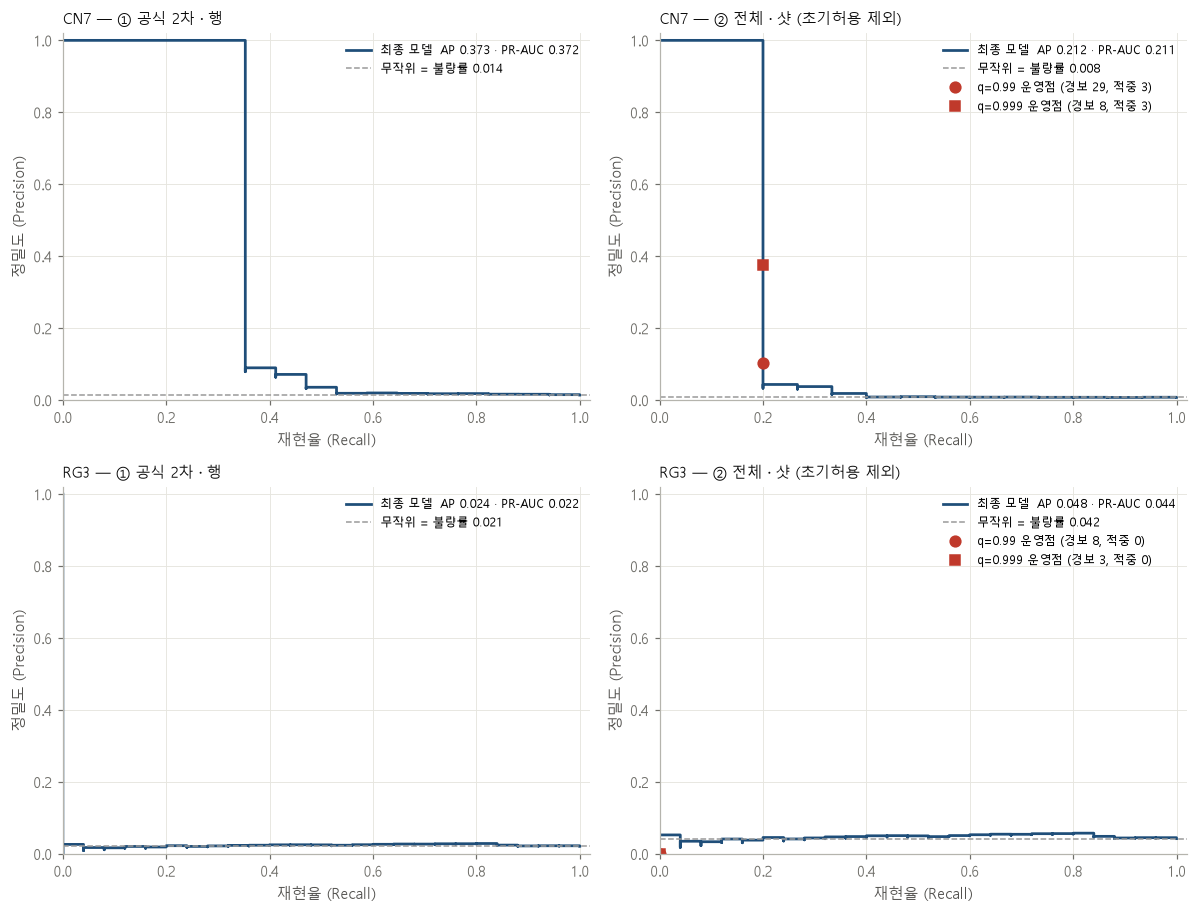

In [6]:
from final_model import plot_pr
c1 = ['제품', '행', '불량 행', 'AP', 'PR-AUC(사다리꼴)', '무작위 PR-AUC(=불량률)', '무작위 평균 대비', '유의']
c2 = ['제품', '샷', '불량', '불량률', 'AP', 'AP_lo', 'AP_hi', 'PR-AUC(사다리꼴)', 'AP/불량률']
print('① 공식 2차 · 행'); display(R['frame1'][c1].round(3))
print('② 전체 · 샷 · 초기허용 제외'); display(R['frame2'][c2].round(3))
plot_pr(R, save_dir='./outputs/final_model')

## 4. 경보 샷 확인 (q = 0.999)

In [7]:
for p, f in R['scores'].items():
    a = f[(f['pct'] >= 0.999) & (f['split'] != '제외') & (f['Reason'] != '초기허용불량')]
    print(p.upper(), f'경보 {len(a)}샷')
    display(a[['TimeStamp', 'run_id', 'PassOrFail', 'Reason', 'score', 'pct']].round(4))

CN7 경보 8샷


C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_17844\3661937591.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(a[['TimeStamp', 'run_id', 'PassOrFail', 'Reason', 'score', 'pct']].round(4))


,TimeStamp,run_id,PassOrFail,Reason,score,pct
58,2020-10-16 05:55:21,cn7_R1,1,미성형,42.1041,0.9998
59,2020-10-16 05:56:22,cn7_R1,1,가스+미성형,43.9536,0.9998
60,2020-10-16 05:57:20,cn7_R1,1,가스+미성형,43.5873,0.9998
604,2020-10-20 06:19:14,cn7_R2,0,정상,25.5538,0.9992
605,2020-10-20 06:20:14,cn7_R2,0,정상,31.1143,0.9996
1260,2020-10-30 02:11:54,cn7_R5,0,정상,38.4059,0.9998
1261,2020-10-30 02:12:54,cn7_R5,0,정상,30.4528,0.9994
1518,2020-11-03 00:40:13,cn7_R6,0,정상,24.1376,0.9990


RG3 경보 3샷


C:\Users\한국전파진흥협회\AppData\Local\Temp\ipykernel_17844\3661937591.py:4: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(a[['TimeStamp', 'run_id', 'PassOrFail', 'Reason', 'score', 'pct']].round(4))


,TimeStamp,run_id,PassOrFail,Reason,score,pct
43,2020-10-22 00:26:10,rg3_R2,0,정상,19.3326,0.9993
44,2020-10-22 00:27:10,rg3_R2,0,정상,19.3242,0.9993
45,2020-10-22 00:28:12,rg3_R2,0,정상,19.3299,0.9993


## 5. (선택) 기존 파생변수 캐시와 비교

In [8]:
for p in ['cn7', 'rg3']:
    print(p); display(compare_with_cache(R, p))

cn7


,변수,최대 절대차,NaN 불일치
0,dev_Max_Injection_Speed,4.440892e-16,0
1,dev_Filling_Time,3.552714e-15,0
2,dev_Max_Injection_Pressure,7.105427e-15,0
3,dev_Max_Switch_Over_Pressure,1.776357e-15,0
4,dev_Average_Back_Pressure,3.552714e-15,0
5,dev_Cushion_Position,0.000000e+00,0
6,dev_Plasticizing_Time,3.552714e-15,0
7,dev_Cycle_Time,2.842171e-14,0
8,fill_anomaly,7.105427e-15,0
9,ev_max_abs_dev,2.842171e-14,0


rg3


,변수,최대 절대차,NaN 불일치
0,dev_Max_Injection_Speed,4.440892e-16,0
1,dev_Filling_Time,0.000000e+00,0
2,dev_Max_Injection_Pressure,4.440892e-16,0
3,dev_Max_Switch_Over_Pressure,3.552714e-15,0
4,dev_Average_Back_Pressure,4.440892e-16,0
5,dev_Cushion_Position,5.551115e-17,0
6,dev_Plasticizing_Time,4.440892e-16,0
7,dev_Cycle_Time,8.881784e-16,0
8,fill_anomaly,2.220446e-16,0
9,ev_max_abs_dev,3.552714e-15,0
